In [1]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

import os
import joblib

In [2]:
rfm = pd.read_csv(
    "../data/processed/customer_rfm.csv",
    index_col="CustomerID"
)

print(rfm.shape)
rfm.head()

(4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


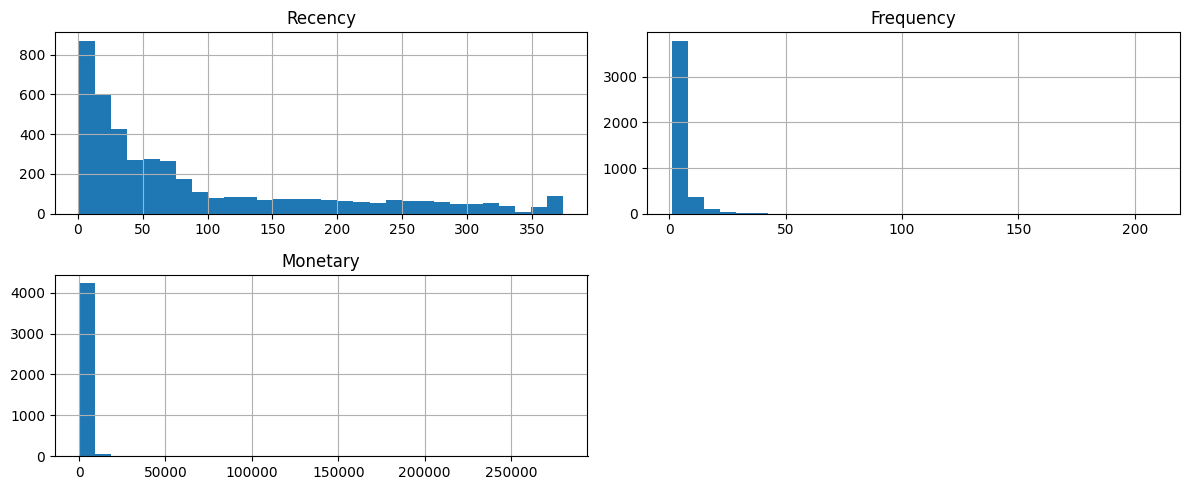

In [3]:
rfm.hist(figsize=(12, 5), bins=30)
plt.tight_layout()
plt.show()

In [4]:
rfm_log = np.log1p(rfm)

rfm_log.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,5.789960,0.693147,11.253955
12347,1.098612,2.079442,8.368925
12348,4.330733,1.609438,7.494564
12349,2.995732,0.693147,7.472245
12350,5.739793,0.693147,5.815324


In [5]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=rfm.columns,
    index=rfm.index
)

rfm_scaled.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514


In [6]:
print("Before Scaling:")
display(rfm_log.describe())

print("After Scaling:")
display(rfm_scaled.describe())

Before Scaling:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,3.830734,1.345582,6.588562
std,1.340261,0.683104,1.258438
min,0.693147,0.693147,1.558145
25%,2.944439,0.693147,5.728418
50%,3.951244,1.098612,6.506636
75%,4.962845,1.791759,7.415535
max,5.926926,5.347108,12.543284


After Scaling:


,Recency,Frequency,Monetary
count,4.338000e+03,4.338000e+03,4.338000e+03
mean,-8.025955e-17,-8.189750e-18,-3.669008e-16
std,1.000115e+00,1.000115e+00,1.000115e+00
min,-2.341296e+00,-9.552143e-01,-3.997811e+00
25%,-6.613615e-01,-9.552143e-01,-6.835802e-01
50%,8.992557e-02,-3.615828e-01,-6.510929e-02
75%,8.447915e-01,6.532370e-01,6.572178e-01
max,1.564198e+00,5.858535e+00,4.732381e+00


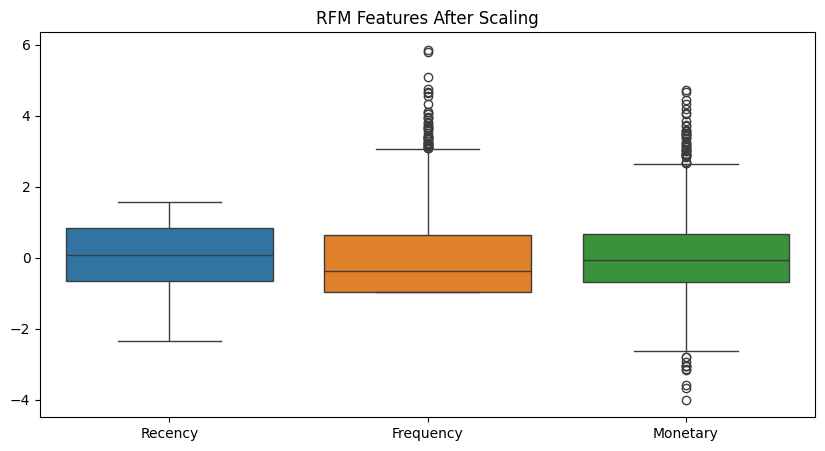

In [7]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=rfm_scaled)

plt.title("RFM Features After Scaling")
plt.show()

In [8]:
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../models", exist_ok=True)

rfm_scaled.to_csv(
    "../data/processed/customer_rfm_scaled.csv"
)

joblib.dump(
    scaler,
    "../models/rfm_scaler.pkl"
)

print("Scaled dataset and scaler saved successfully!")

Scaled dataset and scaler saved successfully!
